In [1]:
import io
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, classification_report, confusion_matrix,
    silhouette_score
)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

RANDOM_STATE = 42
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

In [2]:
UCI_URL = "https://archive.ics.uci.edu/static/public/186/wine+quality.zip"

try:
    response = requests.get(UCI_URL, timeout=30)
    response.raise_for_status()
    archive = zipfile.ZipFile(io.BytesIO(response.content))
    red_path = next(n for n in archive.namelist() if n.endswith("winequality-red.csv"))
    white_path = next(n for n in archive.namelist() if n.endswith("winequality-white.csv"))
    red = pd.read_csv(archive.open(red_path), sep=";")
    white = pd.read_csv(archive.open(white_path), sep=";")
except Exception as exc:
    print("Online download failed:", exc)
    print("Trying local files under ./data/")
    red = pd.read_csv("data/winequality-red.csv", sep=";")
    white = pd.read_csv("data/winequality-white.csv", sep=";")

red["wine_type"] = "red"
white["wine_type"] = "white"
df = pd.concat([red, white], ignore_index=True)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [3]:
display(df.info())
display(df.describe(include="all").T)
print("Duplicate rows:", df.duplicated().sum())
print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False))
print("Quality counts:")
display(df["quality"].value_counts().sort_index())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  wine_type             6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,NaN,NaN,NaN,7.215307,1.296434,3.8,6.4,7.0,7.7,15.9
volatile acidity,6497.0,NaN,NaN,NaN,0.339666,0.164636,0.08,0.23,0.29,0.4,1.58
citric acid,6497.0,NaN,NaN,NaN,0.318633,0.145318,0.0,0.25,0.31,0.39,1.66
residual sugar,6497.0,NaN,NaN,NaN,5.443235,4.757804,0.6,1.8,3.0,8.1,65.8
chlorides,6497.0,NaN,NaN,NaN,0.056034,0.035034,0.009,0.038,0.047,0.065,0.611
free sulfur dioxide,6497.0,NaN,NaN,NaN,30.525319,17.7494,1.0,17.0,29.0,41.0,289.0
total sulfur dioxide,6497.0,NaN,NaN,NaN,115.744574,56.521855,6.0,77.0,118.0,156.0,440.0
density,6497.0,NaN,NaN,NaN,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,NaN,NaN,NaN,3.218501,0.160787,2.72,3.11,3.21,3.32,4.01
sulphates,6497.0,NaN,NaN,NaN,0.531268,0.148806,0.22,0.43,0.51,0.6,2.0


Duplicate rows: 1177
Missing values by column:


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
wine_type               0
dtype: int64

Quality counts:


quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64

In [4]:
data = df.copy()
before = len(data)
data = data.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(data)} duplicate rows; remaining rows: {len(data)}")

# Check basic validity. These measurements should be numeric and non-negative;
# pH is also expected to be positive. Do not silently delete rows without review.
numeric_cols = data.select_dtypes(include=np.number).columns.tolist()
print("Numeric columns:", numeric_cols)
print("Negative numeric values by column:")
display((data[numeric_cols] < 0).sum())

# Ensure target and predictors are numeric where expected.
data["quality"] = pd.to_numeric(data["quality"], errors="coerce")
data = data.dropna(subset=["quality"]).copy()

# Convert source/type field to category for analysis.
data["wine_type"] = data["wine_type"].astype("category")
print("Cleaned shape:", data.shape)

Removed 1177 duplicate rows; remaining rows: 5320
Numeric columns: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']
Negative numeric values by column:


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Cleaned shape: (5320, 13)


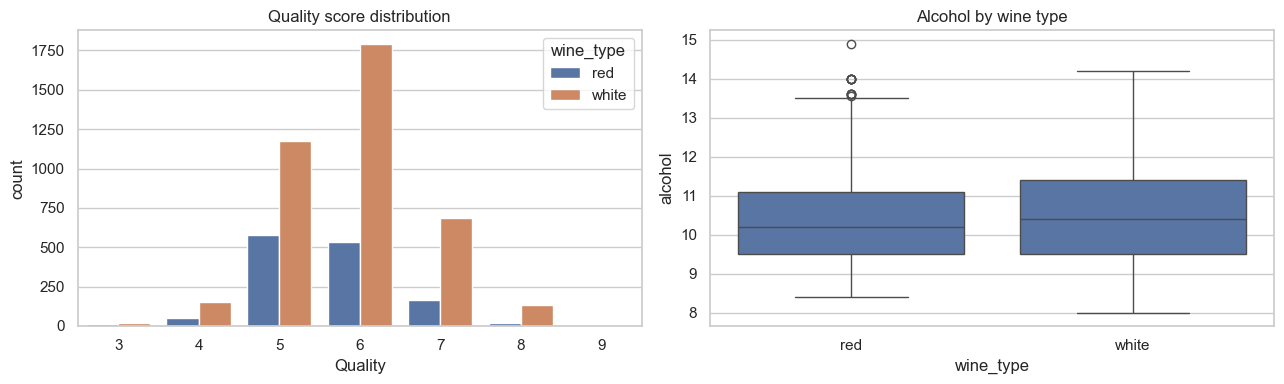

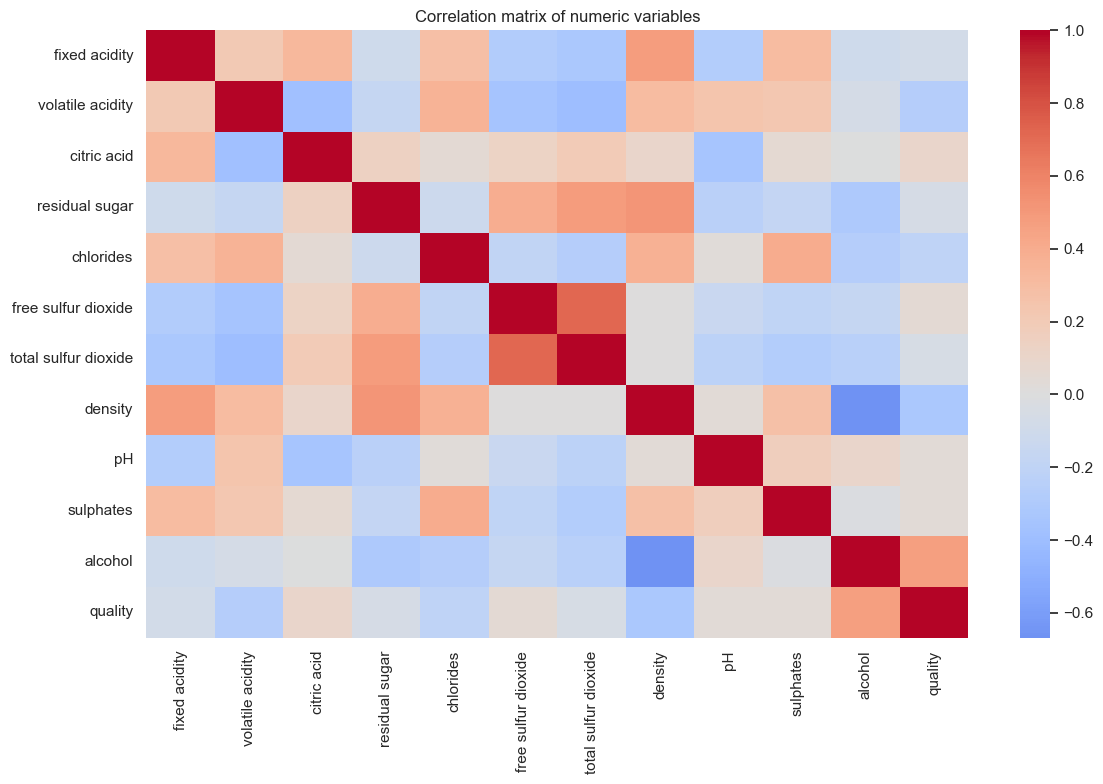

,count,mean,median,std
wine_type,,,,
red,1359,5.623252,6.0,0.823578
white,3961,5.854835,6.0,0.890683


,alcohol,volatile acidity,sulphates,density
quality,,,,
3,10.215000,0.517000,0.506333,0.995744
4,10.215049,0.462379,0.507476,0.994802
5,9.872211,0.393970,0.529041,0.995734
6,10.649060,0.315626,0.534313,0.994377
7,11.511020,0.292342,0.549638,0.992838
8,11.912162,0.302973,0.519054,0.992130
9,12.180000,0.298000,0.466000,0.991460


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=data, x="quality", hue="wine_type", ax=axes[0])
axes[0].set_title("Quality score distribution")
axes[0].set_xlabel("Quality")
sns.boxplot(data=data, x="wine_type", y="alcohol", ax=axes[1])
axes[1].set_title("Alcohol by wine type")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
corr = data.select_dtypes(include=np.number).corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation matrix of numeric variables")
plt.tight_layout()
plt.show()

display(data.groupby("wine_type", observed=True)["quality"].agg(["count", "mean", "median", "std"]))
display(data.groupby("quality")[["alcohol", "volatile acidity", "sulphates", "density"]].mean())

In [6]:
target = "quality"
X = data.drop(columns=[target])
y = data[target].astype(float)

X = pd.get_dummies(X, columns=["wine_type"], drop_first=True, dtype=int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Training rows:", X_train.shape[0], " Test rows:", X_test.shape[0])
print("Features:", X_train.columns.tolist())

Training rows: 4256  Test rows: 1064
Features: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'wine_type_white']


In [7]:
baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DummyRegressor(strategy="mean"))
])
rf_reg = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=300, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    ))
])

models = {"Mean baseline": baseline, "Random Forest": rf_reg}
reg_results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    reg_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "R2": r2_score(y_test, pred)
    })

reg_results = pd.DataFrame(reg_results).sort_values("RMSE")
display(reg_results)

,Model,MAE,RMSE,R2
1,Random Forest,0.509980,0.664436,0.412832
0,Mean baseline,0.694226,0.867579,-0.001093


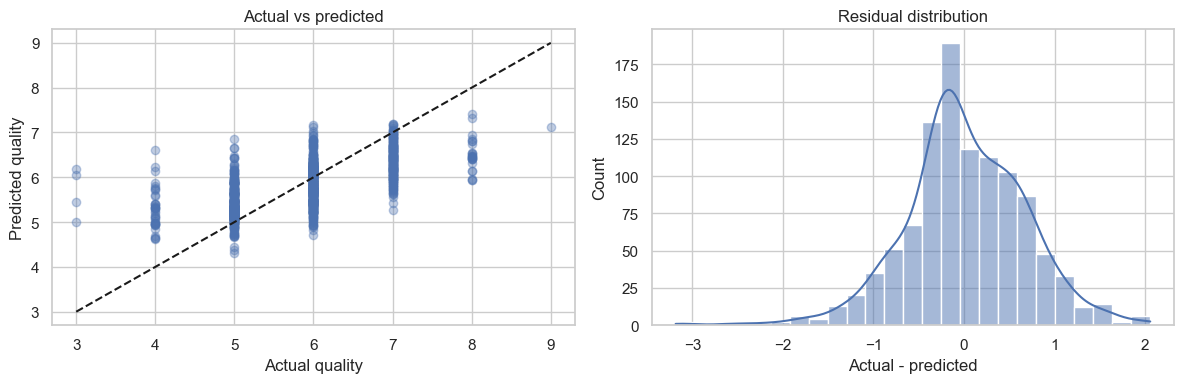

,importance
alcohol,0.278550
volatile acidity,0.118641
free sulfur dioxide,0.091697
sulphates,0.082345
total sulfur dioxide,0.072963
pH,0.068243
residual sugar,0.061159
chlorides,0.058604
citric acid,0.056579
fixed acidity,0.055581


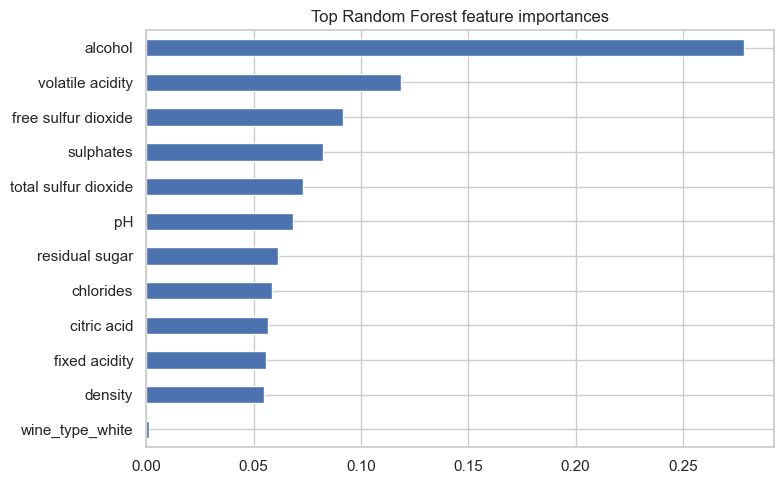

In [8]:
best_model = rf_reg
y_pred = predictions["Random Forest"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_test, y_pred, alpha=0.35)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, "k--")
axes[0].set_xlabel("Actual quality")
axes[0].set_ylabel("Predicted quality")
axes[0].set_title("Actual vs predicted")

residuals = y_test - y_pred
sns.histplot(residuals, bins=25, kde=True, ax=axes[1])
axes[1].set_title("Residual distribution")
axes[1].set_xlabel("Actual - predicted")
plt.tight_layout()
plt.show()

# Feature importance from the fitted random forest
rf = best_model.named_steps["model"]
importance = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
display(importance.head(12).to_frame("importance"))
importance.head(12).sort_values().plot(kind="barh", figsize=(8, 5), title="Top Random Forest feature importances")
plt.tight_layout()
plt.show()

Accuracy: 0.8506
              precision    recall  f1-score   support

 quality < 7       0.88      0.95      0.91       862
quality >= 7       0.66      0.44      0.53       202

    accuracy                           0.85      1064
   macro avg       0.77      0.69      0.72      1064
weighted avg       0.84      0.85      0.84      1064



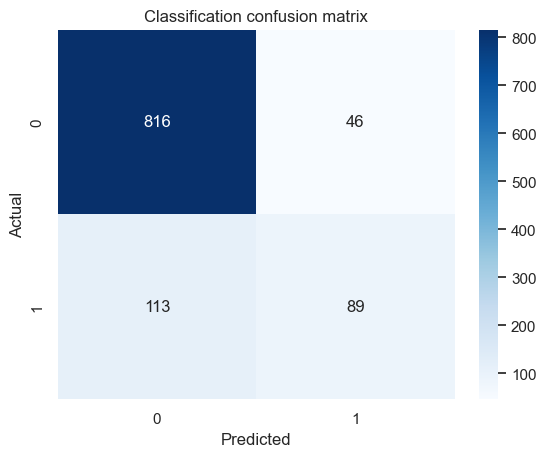

In [9]:
# Optional: run this section if a classification task is useful for your report.
# Define "higher quality" as quality >= 7 for this analysis.
y_class = (data["quality"] >= 7).astype(int)
X_class = pd.get_dummies(data.drop(columns=["quality"]), columns=["wine_type"], drop_first=True, dtype=int)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_class, y_class, test_size=0.20, random_state=RANDOM_STATE, stratify=y_class
)

clf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2,
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
    ))
])
clf.fit(Xc_train, yc_train)
yc_pred = clf.predict(Xc_test)
print("Accuracy:", round(accuracy_score(yc_test, yc_pred), 4))
print(classification_report(yc_test, yc_pred, target_names=["quality < 7", "quality >= 7"], zero_division=0))
sns.heatmap(confusion_matrix(yc_test, yc_pred), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Classification confusion matrix")
plt.show()

,k,silhouette
0,2,0.270442
1,3,0.230022
2,4,0.242775
3,5,0.176891
4,6,0.183043
5,7,0.175739


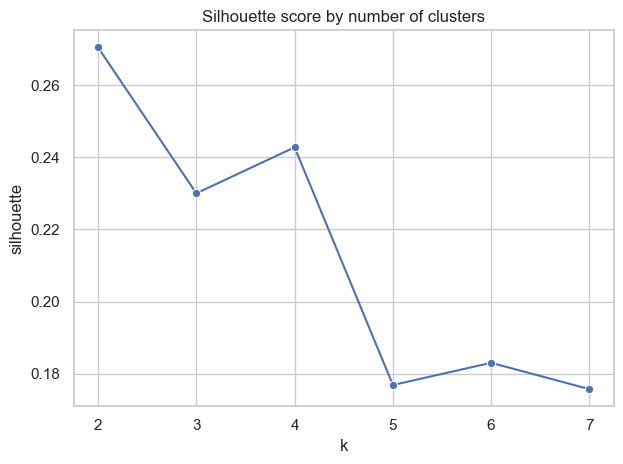

In [10]:
cluster_features = data.select_dtypes(include=np.number).drop(columns=["quality"], errors="ignore")
cluster_features = cluster_features.loc[:, cluster_features.nunique() > 1]

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
Z = scaler.fit_transform(imputer.fit_transform(cluster_features))

silhouette_rows = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(Z)
    silhouette_rows.append({"k": k, "silhouette": silhouette_score(Z, labels)})

silhouette_df = pd.DataFrame(silhouette_rows)
display(silhouette_df)
sns.lineplot(data=silhouette_df, x="k", y="silhouette", marker="o")
plt.title("Silhouette score by number of clusters")
plt.tight_layout()
plt.show()

Selected k: 2


,size,mean_quality,mean_alcohol,mean_volatile_acidity,mean_density
cluster,,,,,
0,3918,5.872,10.600,0.276,0.994
1,1402,5.581,10.406,0.534,0.997


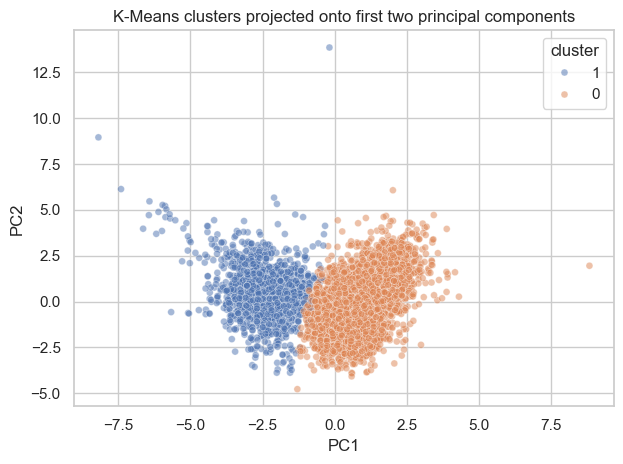

Variance explained by first two PCs: 0.497


In [11]:
best_k = int(silhouette_df.loc[silhouette_df["silhouette"].idxmax(), "k"])
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
clusters = kmeans.fit_predict(Z)

clustered = data.copy()
clustered["cluster"] = clusters
print("Selected k:", best_k)
display(clustered.groupby("cluster").agg(
    size=("quality", "size"),
    mean_quality=("quality", "mean"),
    mean_alcohol=("alcohol", "mean"),
    mean_volatile_acidity=("volatile acidity", "mean"),
    mean_density=("density", "mean")
).round(3))

pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z_2d = pca.fit_transform(Z)
plot_df = pd.DataFrame({"PC1": Z_2d[:, 0], "PC2": Z_2d[:, 1], "cluster": clusters.astype(str)})
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="cluster", alpha=0.5, s=25)
plt.title("K-Means clusters projected onto first two principal components")
plt.tight_layout()
plt.show()
print("Variance explained by first two PCs:", round(pca.explained_variance_ratio_.sum(), 3))

In [12]:
reg_results.to_csv("regression_model_results.csv", index=False)
importance.rename("importance").to_csv("feature_importance.csv")
silhouette_df.to_csv("clustering_silhouette_scores.csv", index=False)
clustered.groupby("cluster").agg(
    size=("quality", "size"),
    mean_quality=("quality", "mean"),
    mean_alcohol=("alcohol", "mean"),
    mean_volatile_acidity=("volatile acidity", "mean"),
    mean_density=("density", "mean")
).to_csv("cluster_profiles.csv")
print("Saved regression_model_results.csv, feature_importance.csv, clustering_silhouette_scores.csv, cluster_profiles.csv")

Saved regression_model_results.csv, feature_importance.csv, clustering_silhouette_scores.csv, cluster_profiles.csv
